<a href="https://colab.research.google.com/github/nikistendo/Niki-Tendolkar-Maker-Portfolio/blob/main/Specific_Disease.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install wfdb shap seaborn scikit-learn -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 108.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.1 which is incompatible.
db-dtypes 1.5.0 requires pandas<3.0.0,>=1.5.3, but you have pandas 3.0.1 which is incompatible.
bqplot 0.12.45 requires pandas<3.0.0,>=1.0.0, but you have pandas 3.0.1 which is incompatible.
dask-cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.1 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.1 which is incompatible.
gradio 5.50.0 requires pandas<3.0,>=1.0, but you have pandas 3.0.1 which is incompatible.


In [ ]:
import pandas as pd
import numpy as np
import torch
import torchvision
from torch.utils.data import Dataset, DataLoader
import os

# Standard device selection logic
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Using device: {device}")

Using device: cuda


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ⚠️  UPDATE this path to where you uploaded Child_ecg.zip
ZIP_PATH    = "/content/drive/MyDrive/Colab Notebooks/md/27078763.zip"
EXTRACT_DIR = '/content/dataset'
ECG_PATH = '/content/dataset/Child_ecg.zip'
EXTRACT_ECG = '/content/dataset/ecg'

!file "{ZIP_PATH}"
stats = os.stat(ZIP_PATH)
print(f"File size: {stats.st_size / (1024 * 1024):.2f} MB")

os.makedirs(EXTRACT_DIR, exist_ok=True)
os.makedirs(EXTRACT_ECG, exist_ok=True)

/content/drive/MyDrive/Colab Notebooks/md/27078763.zip: Zip archive data, at least v1.0 to extract, compression method=store
File size: 3875.36 MB


In [ ]:
print(f"Unzipping {ZIP_PATH} → {EXTRACT_DIR} using 7z...")

# -y assumes 'yes' to all prompts (overwrites)
# -o specifies the output directory
!7z x "{ZIP_PATH}" -o"{EXTRACT_DIR}" -y

print("\nUnzip process finished. Checking contents...")

Unzipping /content/drive/MyDrive/Colab Notebooks/md/27078763.zip → /content/dataset using 7z...

7-Zip [64] 16.02 : Copyright (c) 1999-2016 Igor Pavlov : 2016-05-21
p7zip Version 16.02 (locale=en_US.UTF-8,Utf16=on,HugeFiles=on,64 bits,12 CPUs Intel(R) Xeon(R) CPU @ 2.20GHz (50657),ASM,AES-NI)

Scanning the drive for archives:
  0M Scan /content/drive/MyDrive/Colab Notebooks/md/                                                    1 file, 4063605316 bytes (3876 MiB)

Extracting archive: /content/drive/MyDrive/Colab Notebooks/md/27078763.zip
--
Path = /content/drive/MyDrive/Colab Notebooks/md/27078763.zip
Type = zip
Physical Size = 4063605316

  0%      0% 2 - Child_ecg.zip                        1% 2 - Child_ecg.zip                        2% 2 - Child_ecg.zip            

In [ ]:
print(f"Unzipping {ECG_PATH} → {EXTRACT_ECG} using 7z...")

# -y assumes 'yes' to all prompts (overwrites)
# -o specifies the output directory
!7z x "{ECG_PATH}" -o"{EXTRACT_ECG}" -y

print("\nUnzip process finished. Checking contents...")
# Verify the structure: expecting EXTRACT_DIR/Child_ecg/Pxx/...
if os.path.exists(os.path.join(EXTRACT_ECG, 'Child_ecg')):
    print("Success: 'Child_ecg' folder found.")
else:
    print("Warning: Expected 'Child_ecg' folder not found. Check your ZIP structure.")

Unzipping /content/dataset/Child_ecg.zip → /content/dataset/ecg using 7z...

7-Zip [64] 16.02 : Copyright (c) 1999-2016 Igor Pavlov : 2016-05-21
p7zip Version 16.02 (locale=en_US.UTF-8,Utf16=on,HugeFiles=on,64 bits,12 CPUs Intel(R) Xeon(R) CPU @ 2.20GHz (50657),ASM,AES-NI)

Scanning the drive for archives:
  0M Scan /content/dataset/                           1 file, 1908237306 bytes (1820 MiB)

Extracting archive: /content/dataset/Child_ecg.zip
 10% 4096 Open              --
Path = /content/dataset/Child_ecg.zip
Type = zip
Physical Size = 1908237306
Embedded Stub Size = 4
Total Physical Size = 4055720954
Multivolume = +
Volume Index = 1
Volumes = 2

  0%      0% 157 - Child_ecg/P00/P00041/P00041_E01.dat                                                0% 308 - Child_ecg/P00/P00080/P00080_E01.dat

In [ ]:
print("Unzip complete ✓")
print("Contents:")
for item in sorted(os.listdir(EXTRACT_ECG))[:20]:
    print(f"  {item}")

# Count how many .hea files exist in the extracted directory
total_files = sum([len([f for f in files if f.endswith('.hea')]) for r, d, files in os.walk('/content/dataset/ecg')])
print(f"Extracted records: {total_files} / 14190")

Unzip complete ✓
Contents:
  Child_ecg
Extracted records: 14190 / 14190


Record Name: P00001_E01
Signal Shape: (9000, 9) (samples, leads)
Sampling Frequency: 500 Hz


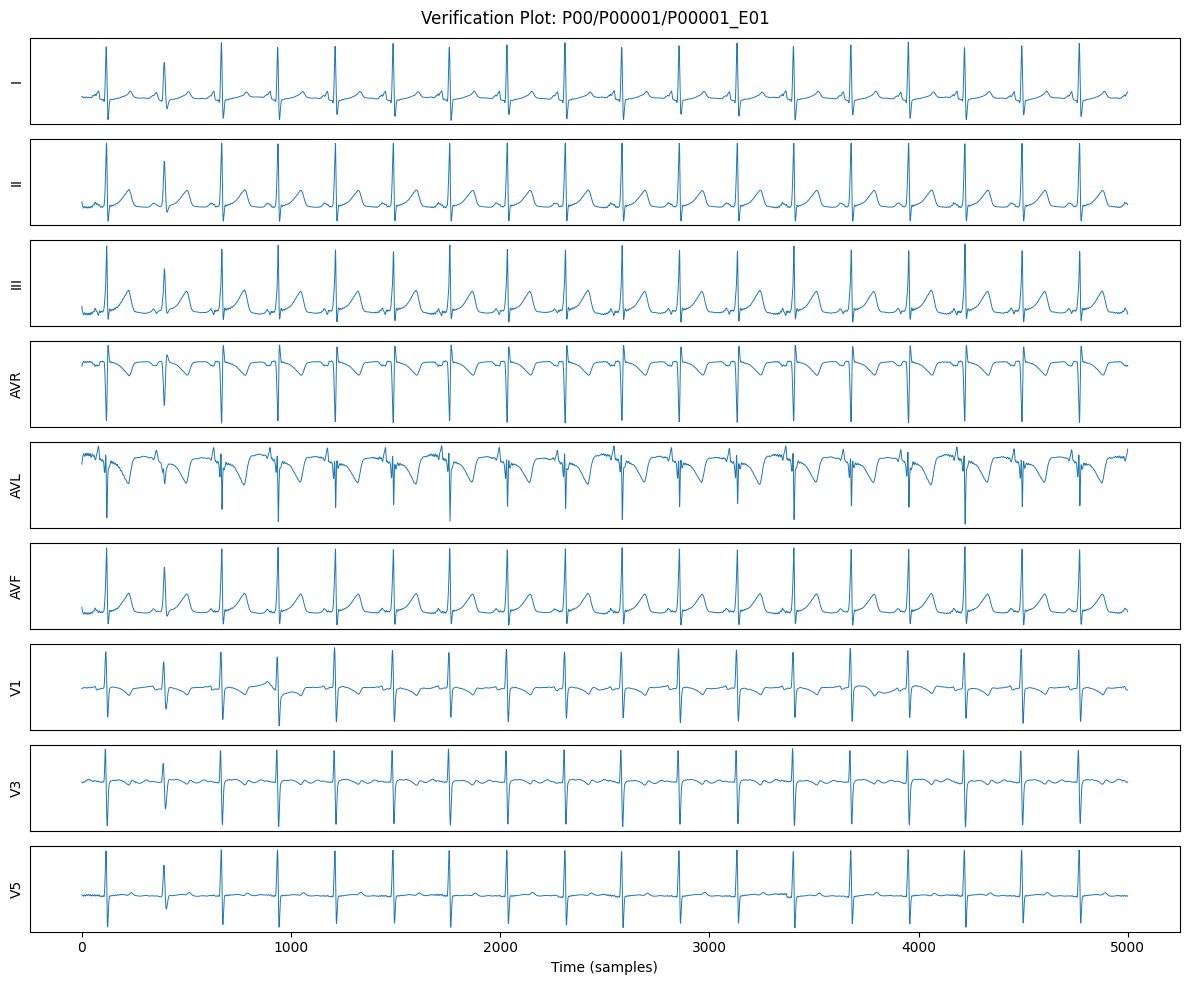

In [ ]:
import wfdb
import matplotlib.pyplot as plt
import numpy as np

# Pick a sample known to be in the first folder (P00)
sample_sub_path = "P00/P00001/P00001_E01"
full_sample_path = os.path.join(EXTRACT_ECG, "Child_ecg", sample_sub_path)

try:
    # Read the record (wfdb automatically looks for .hea and .dat)
    record = wfdb.rdrecord(full_sample_path)
    signals = record.p_signal

    print(f"Record Name: {record.record_name}")
    print(f"Signal Shape: {signals.shape} (samples, leads)")
    print(f"Sampling Frequency: {record.fs} Hz")

    # Plot the first 2 seconds of all available leads
    num_samples_to_plot = int(record.fs * 10)
    plt.figure(figsize=(12, 10))
    for i in range(signals.shape[1]):
        plt.subplot(signals.shape[1], 1, i + 1)
        plt.plot(signals[:num_samples_to_plot, i], linewidth=0.7)
        plt.ylabel(record.sig_name[i])
        plt.yticks([])
        if i < signals.shape[1] - 1: plt.xticks([])

    plt.xlabel("Time (samples)")
    plt.suptitle(f"Verification Plot: {sample_sub_path}")
    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"Error accessing files: {e}")
    print("Double-check that the file exists at:", full_sample_path + ".hea")

In [ ]:
# Load and process the labels
data_path = EXTRACT_DIR
ecg_path = os.path.join(EXTRACT_ECG, "Child_ecg")
print("ECG Path is:",ecg_path)
attr_dict = pd.read_csv(os.path.join(data_path,"AttributesDictionary.csv"))
dis_code = pd.read_csv(os.path.join(data_path,"DiseaseCode.csv"))
print(attr_dict.head())
print(dis_code.head())

ECG Path is: /content/dataset/ecg/Child_ecg
                Filename      ECG_ID Patient_ID    Age    Gender  \
0  P00/P00001/P00001_E01  P00001_E01     P00001   572d  'Female'   
1  P00/P00002/P00002_E01  P00002_E01     P00002  4327d    'Male'   
2  P00/P00003/P00003_E01  P00003_E01     P00003  1087d  'Female'   
3  P00/P00004/P00004_E01  P00004_E01     P00004  2465d    'Male'   
4  P00/P00004/P00004_E02  P00004_E02     P00004  2461d    'Male'   

      Acquisition_date  Sampling_point  Lead  \
0  2017-11-22 10:46:08            9000     9   
1  2017-11-28 21:59:47           15000    12   
2  2017-11-29 16:04:57           10000    12   
3  2017-11-30 15:21:27           13000     9   
4  2017-11-26 19:19:48           15000     9   

                                 AHA_code       CHN_code  \
0  'Left ventricular high voltage';'L147'  'J106';'L123'   
1                                   'C21'          'C13'   
2                                   'C21'          'C13'   
3                 

In [ ]:
# # FOR NOW, use 12-lead only
# attr_dict = attr_dict.loc[attr_dict['Lead'] == 12]

# # Make mapping between ICD-10 code and disease_category
# dis_dict = {}
# for data in dis_code.iterrows():
#     dis_dict[data[1]['ICD-10 Code']] = data[1]['Disease Category']
# dis_dict.popitem() # will print in notebook, but it's gone

# attr_slim = attr_dict.loc[:, ['Patient_ID', 'ECG_ID', 'Age', 'Gender', 'Lead', 'ICD-10 code']]
# attr_slim.drop_duplicates(subset=['Patient_ID'], keep='last', inplace=True)
# attr_slim['ICD-10 code'] = attr_slim['ICD-10 code'].str.replace("'", "", regex=False)
# one_hot = attr_slim['ICD-10 code'].str.get_dummies(sep=';')
# one_hot = one_hot.loc[:, list(dis_dict.keys())]
# one_hot.columns = list(dis_dict.values())
# heart_dis = pd.DataFrame(one_hot.sum(axis=1) > 0, columns=['Heart Disease'])
# attr_slim = pd.concat((attr_slim, heart_dis, one_hot), axis=1)
# attr_slim = attr_slim.sample(n=1500)

# # Read ECG signals and stack into a matrix
# ecg_ids = attr_slim['ECG_ID'].to_list()
# sub_ids = [ecg[:6] for ecg in ecg_ids]

# X = []
# for sub, ecg in zip(sub_ids, ecg_ids):
#     full_path = ecg_path + sub + "/" + ecg + ".csv"
#     x = np.loadtxt(full_path, delimiter=",", skiprows=1)
#     x = x[:, 1:]
#     X.append(np.expand_dims(x, axis=0))
# n_samples = []
# for ecg in X:
#     n_samples.append(ecg.shape[1])
# X = [x for idx, x in enumerate(X) if n_samples[idx] == 15000]
# X = np.concatenate(X, axis=0)

# # Go from one-hot encoded disease labels in Pandas df to integer labels for PyTorch
# y = attr_slim[one_hot.columns].to_numpy()
# y = y[np.array(n_samples) == 15000, :]
# y

In [ ]:
import os
import wfdb
import numpy as np
import pandas as pd

# 1. Filter for 12-lead and then find records that are exactly 30 seconds (15,000 samples)
# We do this before sampling to ensure we actually have data to load
attr_12_lead = attr_dict.loc[attr_dict['Lead'] == 12].copy()

# The dataset paper notes that the sampling rate is 500Hz.
# We need to identify which records in the CSV correspond to the 15000 length.
# If your attr_dict doesn't have a 'Samples' column, we will filter during loading.

# 2. Setup the Disease Mapping (same as before)
dis_dict = {row['ICD-10 Code']: row['Disease Category'] for _, row in dis_code.iterrows()}
attr_12_lead['ICD-10 code'] = attr_12_lead['ICD-10 code'].str.replace("'", "", regex=False)

one_hot = attr_12_lead['ICD-10 code'].str.get_dummies(sep=';')
existing_codes = [code for code in dis_dict.keys() if code in one_hot.columns]
one_hot = one_hot.loc[:, existing_codes]
one_hot.columns = [dis_dict[code] for code in existing_codes]

heart_dis = pd.DataFrame(one_hot.sum(axis=1) > 0, columns=['Heart Disease'])
attr_final = pd.concat((attr_12_lead, heart_dis, one_hot), axis=1)

# 3. Loading with "Find until N" logic
# Instead of random sampling the whole list, we iterate until we find 1500 valid records
X = []
y = []
target_count = 1500
FIXED_LENGTH = 15000

print(f"Searching for {target_count} records with length {FIXED_LENGTH}...")

# Shuffle the attribute list to get a random distribution
attr_shuffled = attr_final.sample(frac=1, random_state=42)

for _, row in attr_shuffled.iterrows():
    if len(X) >= target_count:
        break

    ecg_id = row['Filename']
    sub_id = ecg_id[:6]
    full_path = os.path.join(ecg_path, ecg_id)

    try:
        # Use channels_only=True or just read header first to check length faster
        header = wfdb.rdheader(full_path)
        if header.sig_len == FIXED_LENGTH:
            record = wfdb.rdrecord(full_path)
            X.append(np.expand_dims(record.p_signal, axis=0))
            y.append(row[one_hot.columns].to_numpy())
    except:
        print(full_path)
        continue

if len(X) > 0:
    X = np.concatenate(X, axis=0)
    y = np.array(y)
    print(f"Success! Final Dataset Shape: X={X.shape}, y={y.shape}")
else:
    print("Error: Still no records found. Check if 'ecg_path' is correct.")

Searching for 1500 records with length 15000...
/content/dataset/ecg/Child_ecg/P06/P06104/P06104_E01
/content/dataset/ecg/Child_ecg/P01/P01993/P01993_E01
Success! Final Dataset Shape: X=(1500, 15000, 12), y=(1500, 19)


In [ ]:
def zscore_leads(x, eps=1e-6):
    mean = x.mean(dim=-1, keepdim=True)
    std = x.std(dim=-1, keepdim=True)
    return (x - mean) / (std + eps)

# def maxnorm_leads(x):
#     max = x.max(dim=-1, keepdim=True)
#     return x / max

class ECGDataset(Dataset):
    def __init__(self):
        self.data = torch.tensor(X, dtype=torch.float32)
        self.labels = torch.tensor(y.astype(np.float32), dtype=torch.float32) # Fix: Explicitly cast y to float32

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return zscore_leads(self.data[idx]), self.labels[idx]

dataset = ECGDataset()
# dataloader = DataLoader(dataset, batch_size=100, shuffle=True)
dataloader = DataLoader(dataset,batch_size=64,shuffle=True,num_workers=2,pin_memory=True)

for batch in dataloader:
    print("Batch Data:", batch[0].shape)
    print("Batch Labels:", batch[1])

Batch Data: torch.Size([64, 15000, 12])
Batch Labels: tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]])
Batch Data: torch.Size([64, 15000, 12])
Batch Labels: tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 1.]])
Batch Data: torch.Size([64, 15000, 12])
Batch Labels: tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]])
Batch Data: torch.Size([64, 15000, 12])
Batch Labels: tensor([[0., 0., 0.,  

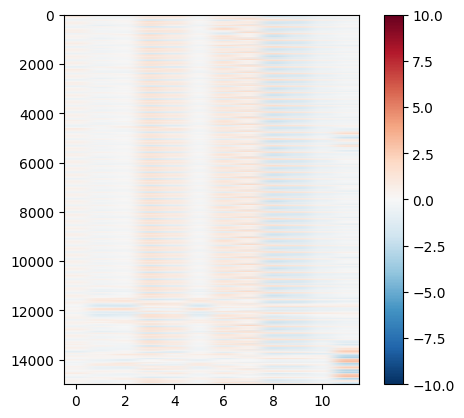

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure()
img = next(iter(dataloader))[0][3, :, :]
caxis = plt.imshow(img, aspect=0.001, cmap="RdBu_r")
plt.colorbar()
caxis.set_clim(-10, 10)

In [ ]:
import torch.nn as nn
import torch.nn.functional as F


class BasicBlock1D(nn.Module):
    def __init__(self, in_ch, out_ch, k=7, stride=1):
        super().__init__()
        pad = k // 2
        self.conv1 = nn.Conv1d(in_ch, out_ch, k, stride=stride, padding=pad, bias=False)
        self.bn1   = nn.BatchNorm1d(out_ch)
        self.relu  = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv1d(out_ch, out_ch, k, stride=1, padding=pad, bias=False)
        self.bn2   = nn.BatchNorm1d(out_ch)

        self.skip = None
        if stride != 1 or in_ch != out_ch:
            self.skip = nn.Sequential(
                nn.Conv1d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm1d(out_ch),
            )

    def forward(self, x):
        identity = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.skip is not None:
            identity = self.skip(identity)
        out = self.relu(out + identity)
        return out

class ECGResNet1D(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv1d(12, 64, kernel_size=15, stride=2, padding=7, bias=False),
            nn.BatchNorm1d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool1d(kernel_size=3, stride=2, padding=1),
        )

        self.stage1 = self._make_stage(64,  64,  blocks=2, k=7, stride=1)
        self.stage2 = self._make_stage(64,  128, blocks=2, k=7, stride=2)
        self.stage3 = self._make_stage(128, 256, blocks=2, k=7, stride=2)

        self.head = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),   # (B, C, 1)
            nn.Flatten(),             # (B, C)
            nn.Dropout(p=0.3),
            nn.Linear(256, n_classes)
        )

    def _make_stage(self, in_ch, out_ch, blocks, k, stride):
        layers = [BasicBlock1D(in_ch, out_ch, k=k, stride=stride)]
        for _ in range(blocks - 1):
            layers.append(BasicBlock1D(out_ch, out_ch, k=k, stride=1))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        return self.head(x)

net = ECGResNet1D(n_classes=19).to(device)

In [ ]:
import torch.nn as nn
import torch.optim as optim

# Use BCEWithLogitsLoss for multi-label classification (19 classes)
# This combines a Sigmoid layer and Binary Cross Entropy for better numerical stability
criterion = nn.BCEWithLogitsLoss()

# Use Adam optimizer - it's more robust than SGD for this type of data
optimizer = optim.Adam(net.parameters(), lr=0.001)

# Optional: Add a learning rate scheduler to lower the LR when the loss plateaus
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=5)

In [ ]:
net.to(device)
net.train()  # Set model to training mode

for epoch in range(40):
    running_loss = 0.0
    epoch_loss = 0.0

    for i, data in enumerate(dataloader, 0):

        # 1. Prepare data
        inputs, labels = data

        # (Batch, Time, Leads) -> (Batch, Leads, Time)
        inputs = torch.permute(inputs, (0, 2, 1)).to(device).float()
        labels = labels.to(device).float()

        # 2. Zero gradients
        optimizer.zero_grad()

        # 3. Forward pass
        outputs = net(inputs)

        # 4. Compute loss
        loss = criterion(outputs, labels)

        # 5. Backprop
        loss.backward()
        optimizer.step()

        # 6. Track losses
        running_loss += loss.item()
        epoch_loss += loss.item()

        if i % 10 == 9:  # Print every 10 batches
            print(f'Epoch [{epoch+1}] | Batch [{i+1}] | Loss: {running_loss/10:.4f}')
            running_loss = 0.0

    # ---- End of epoch ----
    epoch_loss = epoch_loss / len(dataloader)

    # Step scheduler ONCE per epoch
    scheduler.step(epoch_loss)

    print(f'Epoch [{epoch+1}] completed | Avg Loss: {epoch_loss:.4f}')

print("Finished Training")

Epoch [1] | Batch [10] | Loss: 0.0706
Epoch [1] | Batch [20] | Loss: 0.0662
Epoch [2] | Batch [10] | Loss: 0.0640
Epoch [2] | Batch [20] | Loss: 0.0641
Epoch [3] | Batch [10] | Loss: 0.0677
Epoch [3] | Batch [20] | Loss: 0.0604
Epoch [4] | Batch [10] | Loss: 0.0643
Epoch [4] | Batch [20] | Loss: 0.0582
Epoch [5] | Batch [10] | Loss: 0.0628
Epoch [5] | Batch [20] | Loss: 0.0561
Epoch [6] | Batch [10] | Loss: 0.0570
Epoch [6] | Batch [20] | Loss: 0.0601
Epoch [7] | Batch [10] | Loss: 0.0589
Epoch [7] | Batch [20] | Loss: 0.0547
Epoch [8] | Batch [10] | Loss: 0.0503
Epoch [8] | Batch [20] | Loss: 0.0607
Epoch [9] | Batch [10] | Loss: 0.0533
Epoch [9] | Batch [20] | Loss: 0.0556
Epoch [10] | Batch [10] | Loss: 0.0532
Epoch [10] | Batch [20] | Loss: 0.0536
Epoch [11] | Batch [10] | Loss: 0.0532
Epoch [11] | Batch [20] | Loss: 0.0480
Epoch [12] | Batch [10] | Loss: 0.0497
Epoch [12] | Batch [20] | Loss: 0.0521
Epoch [13] | Batch [10] | Loss: 0.0485
Epoch [13] | Batch [20] | Loss: 0.0521
Epoc

In [ ]:
import torch
import numpy as np

net.eval()

all_labels = []
all_probs = []

with torch.no_grad():
    for inputs, labels in dataloader:

        inputs = inputs.permute(0,2,1).to(device).float()
        labels = labels.to(device).float()

        outputs = net(inputs)

        # convert logits → probabilities
        probs = torch.sigmoid(outputs)

        all_probs.append(probs.cpu().numpy())
        all_labels.append(labels.cpu().numpy())

all_probs = np.vstack(all_probs)
all_labels = np.vstack(all_labels)

In [ ]:
y_pred = (all_probs > 0.5).astype(int)
y_true = all_labels

In [ ]:
import numpy as np
from sklearn.metrics import roc_auc_score

aucs = []

for i in range(y_true.shape[1]):

    if len(np.unique(y_true[:, i])) < 2:
        continue   # skip class

    auc = roc_auc_score(y_true[:, i], all_probs[:, i])
    aucs.append(auc)

macro_auc = np.mean(aucs)

print("Macro ROC-AUC:", macro_auc)

Macro ROC-AUC: 0.9968333043971356


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred, zero_division=0))

print("Metric meanings:\n")

print("Precision : Of all samples predicted as a class, how many were correct.")
print("Recall    : Of all true samples of a class, how many the model correctly found.")
print("F1-score  : Harmonic mean of precision and recall (balance between them).")
print("Support   : Number of true samples of that class in the dataset.")

              precision    recall  f1-score   support

           0       1.00      0.70      0.82        10
           1       0.80      0.89      0.84        44
           2       0.70      0.58      0.64        12
           3       0.92      0.70      0.79        33
           4       1.00      1.00      1.00        10
           5       0.00      0.00      0.00         0
           6       1.00      0.60      0.75         5
           7       0.00      0.00      0.00         0
           8       0.80      0.62      0.70        26
           9       1.00      0.76      0.86       100
          10       0.97      0.92      0.94       102
          11       0.80      0.73      0.76        55
          12       1.00      0.50      0.67         4
          13       1.00      0.67      0.80         6
          14       1.00      0.78      0.88         9
          15       0.00      0.00      0.00         1
          16       0.85      0.76      0.81        38
          17       0.00    